# 01. Phân tích Khám phá Dữ liệu (Exploratory Data Analysis - EDA)

Notebook này thực hiện giai đoạn khám phá dữ liệu ban đầu cho dự án **Bơm Rượu (Nhóm 6)**:
1. Thiết lập môi trường và import các thư viện cần thiết.
2. Tải dữ liệu thô `winequality-red.csv` từ thư mục `data/raw/`.
3. Kiểm tra cấu trúc, kiểu dữ liệu và giá trị thiếu (missing values).
4. Thống kê mô tả và phân tích phân phối của các thuộc tính hóa học.
5. Trực quan hóa ma trận tương quan và mối quan hệ giữa các biến.
6. Phân tích đặc trưng, đặc điểm nổi bật trong dữ liệu.
7. Xuất dữ liệu đã xử lý sang thư mục `data/processed/`.

In [2]:
# Import các thư viện cơ bản
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình giao diện hiển thị biểu đồ
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Tải Dữ liệu

Tải tập dữ liệu thô `winequality-red.csv` từ thư mục `../data/raw/`.

In [3]:
# Định nghĩa đường dẫn tương đối so với thư mục notebooks dựa trên cấu trúc dự án của bạn
DATA_DIR = Path("../data")
RAW_DATA_PATH = DATA_DIR / "raw" / "winequality-red.csv"

# Đọc tập dữ liệu
df = pd.read_csv(RAW_DATA_PATH)

# Hiển thị 5 dòng đầu tiên của dữ liệu
display(df.head())

# In kích thước và thông tin tổng quan của dataset
print(f"Kích thước Dataset: {df.shape}")
df.info()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Kích thước Dataset: (1599, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## 2. Kiểm tra Dữ liệu Thiếu và Trùng lặp

Kiểm tra xem tập dữ liệu có chứa giá trị null hoặc các dòng bị trùng lặp hay không.

In [4]:
# Kiểm tra số lượng giá trị thiếu ở mỗi cột
missing_values = df.isnull().sum()
print("Các cột có giá trị thiếu:\n", missing_values[missing_values > 0])

# Kiểm tra số dòng bị trùng lặp
duplicates_count = df.duplicated().sum()
print(f"\nSố lượng dòng trùng lặp: {duplicates_count}")

# Tùy chọn: Xóa các dòng trùng lặp nếu cần thiết để làm sạch dữ liệu
if duplicates_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Đã loại bỏ dòng trùng lặp. Kích thước mới: {df.shape}")

Các cột có giá trị thiếu:
 Series([], dtype: int64)

Số lượng dòng trùng lặp: 240
Đã loại bỏ dòng trùng lặp. Kích thước mới: (1359, 12)


## 3. Thống kê Mô tả

Tạo bảng thống kê mô tả cho các thuộc tính hóa học trong tập dữ liệu rượu vang.

In [5]:
# Thống kê mô tả cho các biến số
display(df.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## 4. Trực quan hóa Khám phá Dữ liệu

Vẽ biểu đồ phân phối và ma trận tương quan để tìm ra các xu hướng ẩn giữa các thành phần hóa học và chất lượng rượu.

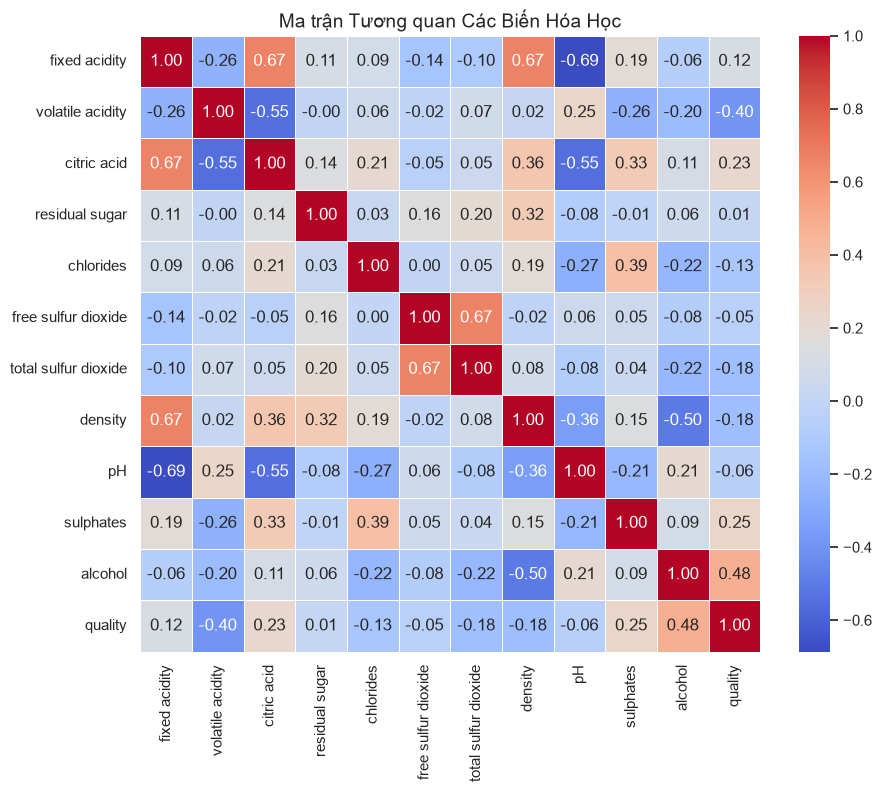

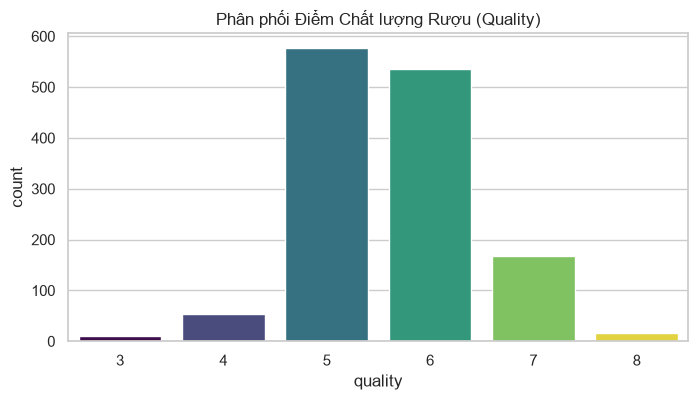

In [6]:
# 1. Ma trận tương quan (Correlation Heatmap cho các biến dạng số)
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Ma trận Tương quan Các Biến Hóa Học", fontsize=14)
plt.show()

# 2. Biểu đồ phân phối của biến mục tiêu 'quality'
plt.figure(figsize=(8, 4))
sns.countplot(x='quality', data=df, hue='quality', palette="viridis", legend=False)
plt.title("Phân phối Điểm Chất lượng Rượu (Quality)")
plt.show()

## 5. Phân tích Đặc trưng và Đặc điểm trong Dữ liệu

Tổng hợp các kết quả khám phá để rút ra đặc điểm cốt lõi của tập dữ liệu rượu vang đỏ:
- **Phân phối điểm số:** Điểm chất lượng (`quality`) tập trung chủ yếu ở mức trung bình (5 và 6), dữ liệu có hiện tượng mất cân bằng ở các điểm số thấp và cao.
- **Tương quan mạnh:** Xác định các chỉ số hóa học ảnh hưởng trực tiếp đến chất lượng rượu (tương quan dương/âm).

In [7]:
# 1. Phân tích tương quan cụ thể với biến mục tiêu 'quality'
print("=== ĐẶC TRƯNG TƯƠNG QUAN VỚI CHẤT LƯỢNG RƯỢU (QUALITY) ===")
quality_corr = corr_matrix['quality'].sort_values(ascending=False)
display(quality_corr)

# 2. Trích xuất tự động các đặc điểm nổi bật (Dùng .to_list() và .iloc để tránh lỗi KeyError)
corr_index_list = quality_corr.index.to_list()
highest_pos_feature = corr_index_list[1] # Bỏ qua chính 'quality' ở vị trí 0
highest_neg_feature = corr_index_list[-1]

print(f"\n--- NHẬN XÉT ĐẶC ĐIỂM DỮ LIỆU ---")
print(f"• Tổng số mẫu sau xử lý: {df.shape[0]} dòng, {df.shape[1]} cột đặc trưng.")
print(f"• Đặc trưng có tương quan dương mạnh nhất với chất lượng rượu là: **{highest_pos_feature}** (hệ số: {quality_corr.iloc[1]:.2f})")
print(f"• Đặc trưng có tương quan âm mạnh nhất với chất lượng rượu là: **{highest_neg_feature}** (hệ số: {quality_corr.iloc[-1]:.2f})")
print(f"• Tổng số giá trị thiếu hiện tại: {df.isnull().sum().sum()} giá trị.")

=== ĐẶC TRƯNG TƯƠNG QUAN VỚI CHẤT LƯỢNG RƯỢU (QUALITY) ===


quality                 1.000000
alcohol                 0.480343
sulphates               0.248835
citric acid             0.228057
fixed acidity           0.119024
residual sugar          0.013640
free sulfur dioxide    -0.050463
pH                     -0.055245
chlorides              -0.130988
total sulfur dioxide   -0.177855
density                -0.184252
volatile acidity       -0.395214
Name: quality, dtype: float64


--- NHẬN XÉT ĐẶC ĐIỂM DỮ LIỆU ---
• Tổng số mẫu sau xử lý: 1359 dòng, 12 cột đặc trưng.
• Đặc trưng có tương quan dương mạnh nhất với chất lượng rượu là: **alcohol** (hệ số: 0.48)
• Đặc trưng có tương quan âm mạnh nhất với chất lượng rượu là: **volatile acidity** (hệ số: -0.40)
• Tổng số giá trị thiếu hiện tại: 0 giá trị.


## 6. Xuất Dữ liệu Đã Xử Lý

Lưu tập dữ liệu đã kiểm tra và làm sạch vào đường dẫn `../data/processed/winequality-red-cleaned.csv` theo đúng cấu trúc yêu cầu của dự án.

In [8]:
# Đảm bảo thư mục processed đã tồn tại
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Lưu dataframe đã xử lý với tên tệp theo đúng yêu cầu
PROCESSED_FILE_PATH = PROCESSED_DIR / "winequality-red-cleaned.csv"
df.to_csv(PROCESSED_FILE_PATH, index=False)

print(f"Đã lưu dataset đã xử lý thành công vào: {PROCESSED_FILE_PATH}")

Đã lưu dataset đã xử lý thành công vào: ..\data\processed\winequality-red-cleaned.csv
